# Laboratorio di Analisi Numerica
## Lezione 7

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
20 novembre 2024

*Conversione della dispensa «Laboratorio_07.tex»; data mantenuta dall’originale.*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra` e `Plots`. Se necessario, installate una sola volta il pacchetto grafico con `using Pkg; Pkg.add("Plots")`.

Eseguite le celle dall’alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite. Ogni notebook è indipendente dagli altri.

In [ ]:
using LinearAlgebra
using Plots

## 1. Jacobi e Gauss–Seidel per un problema differenziale in due dimensioni

### 1.1. Problema e modello

Calcoliamo la forma di una membrana elastica rettangolare, fissata lungo tutto il bordo. È la versione bidimensionale della corda fissata agli estremi vista nella lezione 4.

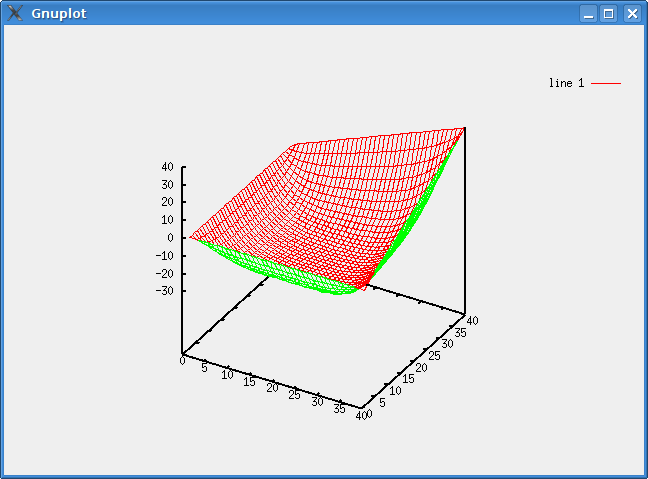

Membrana elastica con bordo fissato (figura della dispensa originale).

Discretizziamo la membrana con una griglia di $m\times n$ punti materiali. Il punto $(i,j)$ ha altezza $z_{i,j}$ e carico verso il basso $p_{i,j}$. I punti $(1,j),(m,j),(i,1),(i,n)$ hanno altezze fissate. Su ogni punto interno agiscono il peso e le tensioni dei quattro vicini.

La componente verticale della tensione verso $(i,j+1)$ è proporzionale a $z_{i,j+1}-z_{i,j}$. Indicando la costante di proporzionalità con $\kappa$, l’equilibrio richiede

$$p_{i,j}=\kappa\left(z_{i+1,j}+z_{i-1,j}+z_{i,j+1}+z_{i,j-1}-4z_{i,j}\right),\qquad i=2,\ldots,m-1,\ j=2,\ldots,n-1.$$

*Nota di trascrizione:* la didascalia originale usa $\kappa^{-1}$ per la tensione, mentre l’equazione usa $\kappa$. Qui adottiamo la convenzione dell’equazione; negli esercizi porremo $\kappa=1$.

Non ci sono equazioni per le altezze al bordo, che sono già note. Per $m=n=5$, ordinando le incognite come $(z_{22},z_{23},z_{24},z_{32},\ldots,z_{44})$, il sistema è

$$
\begin{bmatrix}
B&I&0\\ I&B&I\\0&I&B
\end{bmatrix}
\begin{bmatrix}z_{22}\\z_{23}\\z_{24}\\z_{32}\\z_{33}\\z_{34}\\z_{42}\\z_{43}\\z_{44}\end{bmatrix}
=
\begin{bmatrix}
\kappa^{-1}p_{22}-z_{12}-z_{21}\\
\kappa^{-1}p_{23}-z_{13}\\
\kappa^{-1}p_{24}-z_{14}-z_{25}\\
\kappa^{-1}p_{32}-z_{31}\\
\kappa^{-1}p_{33}\\
\kappa^{-1}p_{34}-z_{35}\\
\kappa^{-1}p_{42}-z_{41}-z_{52}\\
\kappa^{-1}p_{43}-z_{53}\\
\kappa^{-1}p_{44}-z_{54}-z_{45}
\end{bmatrix},\qquad
B=\begin{bmatrix}-4&1&0\\1&-4&1\\0&1&-4\end{bmatrix},\quad I=I_3.
$$

La soluzione contiene gli elementi di `z[2:m-1, 2:n-1]` messi in colonna in un ordine scelto. **Julia:** `vec` ordina per colonne, mentre l’ordine mostrato sopra percorre le righe; se costruite il sistema esplicito, mantenete coerenti matrice, termine noto e ordinamento.

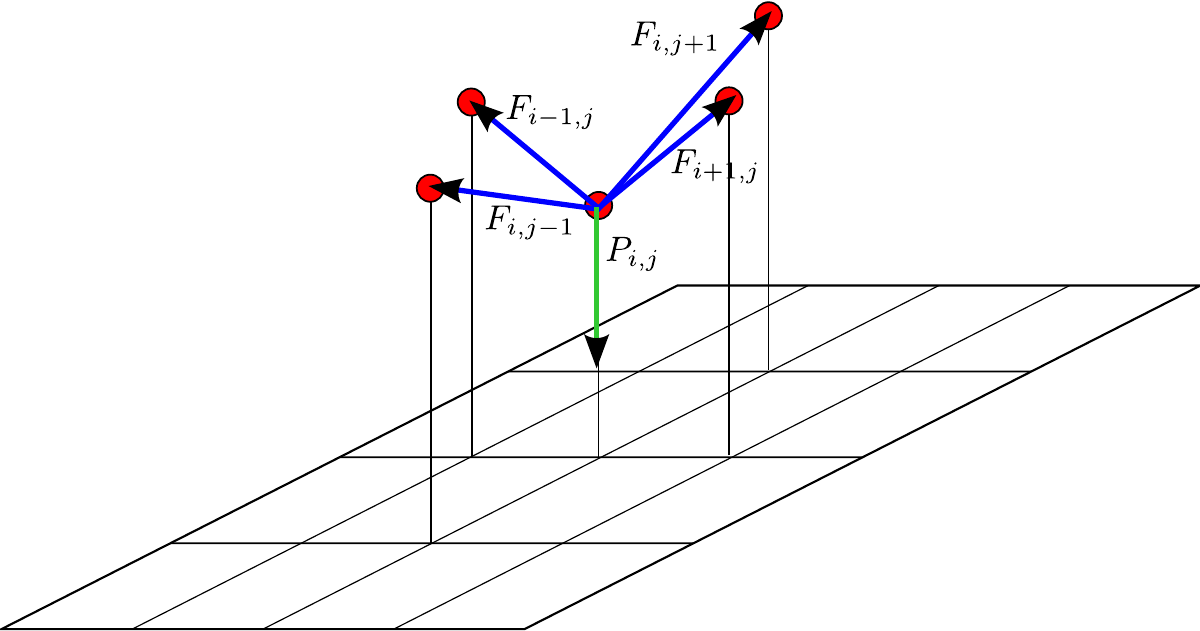

Forza peso e tensioni verso i quattro vicini (dispensa originale).

### 1.2. Iterazioni senza costruire la matrice

Una soluzione diretta **densa** costa $O(((m-2)(n-2))^3)$; la matrice è in realtà sparsa. Qui evitiamo di costruirla e lavoriamo direttamente sulla griglia:

$$z_{i,j}\leftarrow\frac{z_{i-1,j}+z_{i+1,j}+z_{i,j-1}+z_{i,j+1}-\kappa^{-1}p_{i,j}}{4}.$$

Aggiorniamo solo i punti interni, lasciando invariato il bordo.

### Esercizio 1

Verificate che le istruzioni di aggiornamento di Jacobi e Gauss–Seidel per il sistema precedente hanno proprio questa forma. Quali altezze appartengono al passo precedente e quali al passo corrente?

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 1.*

### Esercizio 2

Scrivete `membrana(bordo, carico, r)`:

- `bordo` è una matrice $m\times n$ le cui entrate sul bordo contengono le altezze fissate;
- `carico` è una matrice della stessa dimensione contenente i pesi;
- `r` è il numero di iterazioni.

La funzione deve eseguire `r` passi di Gauss–Seidel (oppure Jacobi), con $\kappa=1$, e restituire la matrice delle altezze. Non costruite il sistema lineare esplicito.

**Julia:** iniziate con `z = float.(bordo)`, così da non modificare l’input. Per Jacobi usate una copia della griglia precedente a ogni passo; per Gauss–Seidel aggiornate direttamente `z[i,j]`. I cicli percorrono `2:m-1` e `2:n-1`.

Per visualizzare il risultato usate `surface`, oppure `wireframe` per una griglia simile a `mesh` di MATLAB. Le colonne rappresentano l’asse orizzontale, le righe l’altro asse.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 2

In [ ]:
m = 40
n = 40
bordo = zeros(m, n)
carico = ones(m, n)
# z = membrana(bordo, carico, 500)
# surface(1:n, 1:m, z; xlabel="j", ylabel="i", zlabel="altezza", legend=false)
# wireframe(1:n, 1:m, z; xlabel="j", ylabel="i", zlabel="altezza", legend=false)

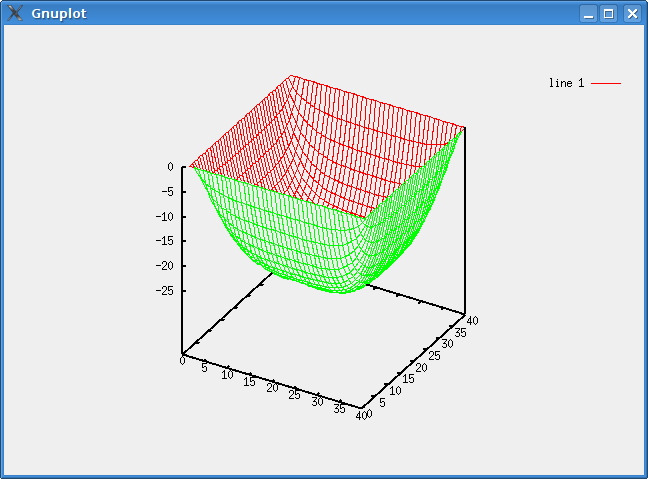

Forma della membrana con bordo nullo e carico uniforme (dispensa originale).

### Esercizio 3

Sperimentate cambiando i dati:

1. Modificate `carico`: appoggiate un peso distribuito su una regione, oppure fate pesare la metà destra $1$ e quella sinistra $2$.
2. Modificate `bordo`: bordo sinistro ad altezza $1$, destro ad altezza $n$, e valori $1,\ldots,n$ sui bordi superiore e inferiore. Che cosa cambia se le altezze al bordo sono discontinue?
3. Appoggiate un peso su un solo punto della membrana.

Usate `.=` per assegnare uno scalare a una porzione di matrice. Non dimenticate di raccordare coerentemente gli angoli.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 3

In [ ]:
# Esempi di dati, da usare con membrana:
carico_asimmetrico = ones(m, n)
carico_asimmetrico[:, 1:div(n, 2)] .= 2
bordo_inclinato = zeros(m, n)
bordo_inclinato[:, 1] .= 1
bordo_inclinato[:, end] .= n
bordo_inclinato[1, :] = 1:n
bordo_inclinato[end, :] = 1:n
carico_puntuale = zeros(m, n)
carico_puntuale[div(m, 2), div(n, 2)] = 100

## 2. Esercizi facoltativi

### Esercizio 4 (facoltativo)

Chi converge più velocemente, Jacobi o Gauss–Seidel? Confrontate a parità di dati e criterio di arresto. Se avete visto il teorema di Stein–Rosenberg, provate a prevederlo teoricamente.

Potete misurare il residuo sulle sole equazioni interne: $R_{ij}=z_{i-1,j}+z_{i+1,j}+z_{i,j-1}+z_{i,j+1}-4z_{i,j}-p_{i,j}$. `norm(R)` è la norma di Frobenius della matrice, uguale alla norma euclidea di `vec(R)`.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 4

### Esercizio 5 (facoltativo)

Come risolvereste lo stesso problema su una superficie non rettangolare, senza costruire esplicitamente la matrice? Considerate una maschera che distingua punti interni, punti sul bordo e punti esterni.

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 5.*

### 2.1. Metodi multigrid

Gauss–Seidel può partire da una stima migliore della soluzione, ottenuta risolvendo il problema su una griglia più larga. Si risolve un problema più piccolo e si interpolano le altezze mancanti per inizializzare il problema grande.

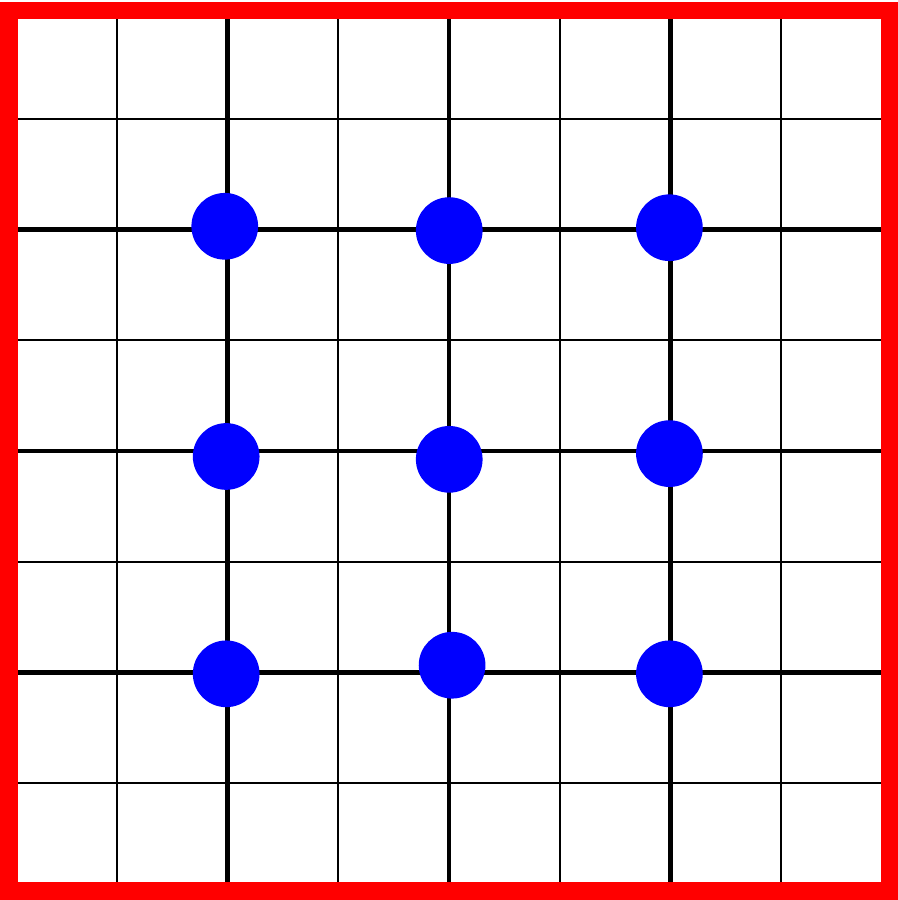

Griglia fine, bordo rosso e punti della griglia grossolana in blu (dispensa originale).

### Esercizio 6 (facoltativo)

Supponete $m=n=2^{k+1}+1$ e scrivete una funzione che:

1. Restringa carichi e altezze al bordo a una griglia $(2^k+1)\times(2^k+1)$.
2. Risolva il sistema piccolo.
3. Estenda la soluzione alla griglia fine, approssimando i valori mancanti.
4. Usi questa stima come punto iniziale per Gauss–Seidel.

Potete applicare il procedimento ricorsivamente. In Julia la griglia grossolana seleziona gli indici `1:2:m` e `1:2:n`. Come interpolate i punti mancanti?

**Scala del carico:** se le due griglie discretizzano lo stesso problema $\Delta z=f$, il termine noto discreto è $h^2f$. Raddoppiando il passo, tenete conto del fattore $4$ nel carico della griglia grossolana. Dichiarate la convenzione scelta per il carico e mantenete le altezze del bordo. Per usare la stima interpolata potete inizializzare anche l’interno di `bordo`, oppure aggiungere un parametro iniziale alla funzione.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 6